# Expulsion of Germans after WW2: migration in West Germany (1950)

County-level maps and state-level charts based on the 1950 West German census, linked to IPUMS MOSAIC county shapes via `bridge.csv`. Sources are listed in `README.md`.

Run the cells from top to bottom. The notebook uses the MATLAB kernel ([MATLAB Integration for Jupyter](https://github.com/mathworks/jupyter-matlab-proxy)) and expects the project folder as the working directory.

Helper functions: `add_lindau.m`, `get_ipums_table.m`, `get_state_rows.m`, `plot_quintile_map.m`.

## Global settings

In [21]:
% Save every chart to chart_folder right after it is drawn
SAVE = true;

% Output folder for the saved charts
chart_folder = 'charts';
if SAVE && ~isfolder(chart_folder)
    mkdir(chart_folder);
end

my_step_colormap = [
    247, 247, 247;
    204, 204, 204;
    150, 150, 150;
     99,  99,  99;
     37,  37,  37
] / 255;

% Font size used in all figures
myfontsize = 10;

% West German states shown in the state-level charts
land_names = {
    'Schleswig-Holstein', 'Hamburg', 'Bremen', 'Niedersachsen', ...
    'Nordrhein-Westfalen', 'Hessen', 'Rheinland-Pfalz', 'Baden-Württemberg', ...
    'Bayern'};

## Read bridge data

In [22]:
% bridge.csv maps census county IDs to IPUMS county IDs (KREIS_KENN).
% census_id follows table 7, census_id_tab6_16 the numbering of tables 6 and 16
% (bridge.csv is built from bridge_old.csv by make_bridge.m).
% IDs are read as strings to keep leading zeros and spaces intact.
file = 'bridge.csv';

opts = detectImportOptions(file, 'TextType', 'string');

opts = setvartype(opts, {'census_id', 'census_id_tab6_16', 'ipums_id'}, 'string');

opts.SelectedVariableNames = {'census_id', 'census_id_tab6_16', 'ipums_id'};

bridge = readtable(file, opts);

% County shapes from IPUMS (state of 1950)
shapes_ipums = readgeotable('germany_ipums/niemcy_1949_1989/Germany_1950_v.1.0.shp');

## Read expellee population (table 6)

In [23]:
% Table 6: total population and number of expellees per county (13.09.1950).
% Data starts at column D (County ID).
file = 'sources/tab6vz1950population-expellees.xlsx';

opts = detectImportOptions(file, 'Sheet', 2, ...
    'VariableNamesRange', '', ...
    'DataRange', 'D4', ...
    'VariableNamingRule', 'preserve', ...
    'TextType', 'string');

opts.VariableNames = {'county_id', 'county_name', 'total_population', 'total_expellees'};

expellee_population = readtable(file, opts);

expellee_population = add_lindau(expellee_population);

% Table 6 uses its own county numbering
expellee_population_ipums = get_ipums_table(expellee_population, bridge, shapes_ipums, ...
    'census_id_tab6_16');

## Read 1939 residency (table 7)

In [24]:
% Table 7: 1950 population by place of residence on 1 September 1939.
% The header spans two rows: row 2 holds main categories, row 3 holds
% sub-categories.
file = 'sources/tab7vz1950population-by-place-of-residence-on-september-1-1939-org.xlsx';

raw_headers = readcell(file, 'Sheet', 2, 'Range', '2:3');

h0 = {'county_id', 'county_name'};
h1 = string(raw_headers(1, :));
h2 = string(raw_headers(2, :));

% Use the sub-category name if present, otherwise the main category name
for i = (1:length(h2))
    if ismissing(h2(i))
        h2(i) = h1(i);
    end
end

h2 = [h0, h2];

opts = detectImportOptions(file, 'Sheet', 2, ...
    'VariableNamesRange', '', ...
    'DataRange', 'D7', ...
    'VariableNamingRule', 'preserve', ...
    'TextType', 'string');

opts.VariableNames = h2;

% Selected columns
opts.SelectedVariableNames = {
    'county_id', 'county_name', ...
    'in the same State', 'in another state of the Federal Republic', ...
    'in Berlin', 'in another state of the Soviet Occupation Zone', ...
    'in the German eastern territories under foreign administration and in the Saar region', ...
    'Silesia', 'Brandenburg', 'Pommerania', 'East Prussia', 'Saar region', ...
    ...
    'abroad', 'Austria', 'Czechoslovakia', 'Poland', 'Gdansk', 'Switzerland', ...
    'Soviet Union', 'former Baltic States', 'former Memel Territory', 'Hungary', ...
    'Yugoslavia', 'Romania', 'Italy', 'rest of south and south east Europe', ...
    'France', 'Belgium', 'Netherlands', ...
    'Luxembourg', 'Great Britain', 'Denmark', ...
    ...
    'non European States', 'Chian and Japan', 'rest of Asia', ...
    'USA', 'Canada', 'Brazil', ...
    'Argentinia', 'rest of America', 'South African Union', 'rest of Africa', ...
    'Australia', 'Oceania'
};

population_1939 = readtable(file, opts);

% Replacement names
population_1939.Properties.VariableNames = {
    'county_id', 'county_name', ...
    'same_state', 'another_state', 'berlin', 'gdr', 'east_admin_and_saar', ...
    'silesia', 'brandenburg', 'pomerania', 'east_prussia', 'saar', ...
    ...
    'abroad', 'austria', 'czechoslovakia', 'poland', 'gdansk', 'switzerland', ...
    'soviet_union', 'former_baltic_states', 'former_memel_territory', 'hungary', ...
    'yugoslavia', 'romania', 'italy', 'rest_of_south_and_southeast_europe', ...
    'france', 'belgium', 'netherlands', ...
    'luxembourg', 'great_britain', 'denmark', ...
    ...
    'non_european_states', 'china_and_japan', 'rest_of_asia', ...
    'usa', 'canada', 'brazil', ...
    'argentina', 'rest_of_america', 'south_african_union', 'rest_of_africa', ...
    'australia', 'oceania'
};

population_1939 = add_lindau(population_1939);

misc_n_rhein = {'Landesteil Nordrhein', 'Landesteil Westfalen'};
mask_n_rhein = population_1939.county_id.startsWith('14') | ...
    matches(population_1939.county_name, misc_n_rhein);
cols = {'silesia', 'brandenburg', 'pomerania', 'east_prussia', 'saar'};
n_rhein_east = population_1939(mask_n_rhein, cols);
n_rhein_east_sum = sum(n_rhein_east, 2);
population_1939(mask_n_rhein, 'east_admin_and_saar') = n_rhein_east_sum;

population_1939_ipums = get_ipums_table(population_1939, bridge, shapes_ipums);

## Read war destruction (table 16)

In [25]:
% Table 16: normal dwellings in total and those affected by war damages (1950).
% Absolute counts are read (not the source's share column), so that Lindau
% can be added to Bayern before the share is computed.
file = 'sources/tab16gz1950war-destructions.xlsx';

opts = detectImportOptions(file, 'Sheet', 2, ...
    'VariableNamesRange', 'A2', ...
    'DataRange', 'A4', ...
    'VariableNamingRule', 'preserve', ...
    'TextType', 'string');

opts.SelectedVariableNames = { ...
    'County ID', 'County Name', 'Normal dwellings (total)', ...
    'Normal dwellings affected by war damages'};

war_destruction = readtable(file, opts);

war_destruction.Properties.VariableNames = { ...
    'county_id', 'county_name', 'total_dwellings', 'damaged_dwellings'};

war_destruction = add_lindau(war_destruction);

% Share of damaged dwellings in %
war_destruction.damaged_percentage = ...
    war_destruction.damaged_dwellings ./ war_destruction.total_dwellings .* 100;

% Table 16 uses the same county numbering as table 6
war_destruction_ipums = get_ipums_table(war_destruction, bridge, shapes_ipums, ...
    'census_id_tab6_16');

## Prepare data for charts

In [26]:
% State-level rows (one per Land, in the order of land_names)
state_expellees = get_state_rows(expellee_population, land_names);
state_1939 = get_state_rows(population_1939, land_names);

% Add the 1950 total population to the 1939 residency table,
% it is the denominator for all residency maps. The tables number some
% counties differently, so table 6 is matched via census_id_tab6_16.
county_population = expellee_population(:, {'county_id', 'total_population'});

population_1939_ipums = innerjoin(population_1939_ipums, county_population, ...
    'LeftKeys', 'census_id_tab6_16', 'RightKeys', 'county_id');

## Bar chart: expellees vs. native population per state

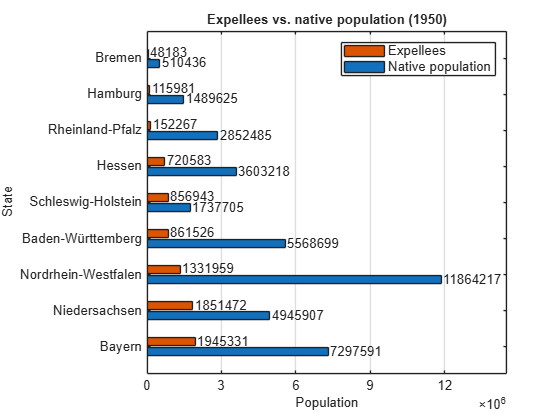

In [27]:
% Native population = total population minus expellees
expellees = state_expellees.total_expellees;
native = state_expellees.total_population - expellees;
states = state_expellees.county_name;

% Sort states by the number of expellees
[sorted_expellees, idx] = sort(expellees, "descend");

sorted_native = native(idx);
sorted_states = cellstr(states(idx));

plot_data = [sorted_native, sorted_expellees];

% Chart
fig = figure();

b = barh(sorted_states, plot_data, 'grouped');

xlabel('Population');
ylabel("State")

legend({'Native population', 'Expellees'}, 'Location', 'northeast');

title('Expellees vs. native population (1950)');

set(gca, 'XGrid', 'on');

xlim([0, 14500000]);
xticks(0:3000000:15000000)

% Value labels for series 1 (native population)
xtips = b(1).YEndPoints + 0.005 * max(xticks); % Small shift to the right
ytips = b(1).XEndPoints;
labels = string(b(1).YData);
text(xtips, ytips, labels, 'HorizontalAlignment','left', ...
    'VerticalAlignment','middle','FontSize',8);

% Value labels for series 2 (expellees)
xtips = b(2).YEndPoints + 0.005 * max(xticks); % Small shift to the right
ytips = b(2).XEndPoints;
labels = string(b(2).YData);
text(xtips, ytips, labels, 'HorizontalAlignment','left', ...
    'VerticalAlignment','middle','FontSize',8);

fontsize(fig, myfontsize, "points")

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '01_expellees_vs_native_population.png'), Resolution=300);
end

## Map: migration from other West German states

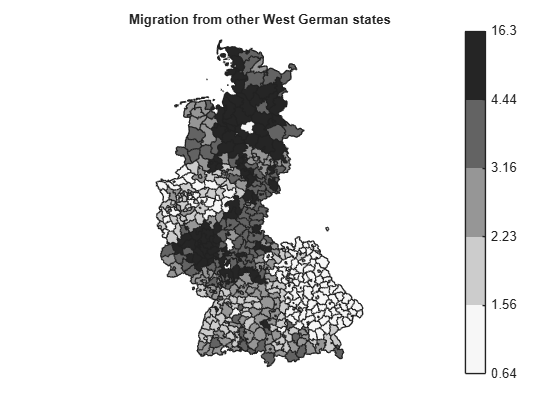

In [28]:
col = 'another_state';

% Share of the 1950 population in %
base = population_1939_ipums(:, {'Shape', col});
base{:, col} = base{:, col} ./ population_1939_ipums.total_population .* 100;

fig = plot_quintile_map(base, col, ...
    'Migration from other West German states', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '02_map_migration_other_states.png'), Resolution=300);
end

## Map: migration from East Germany (Soviet zone)

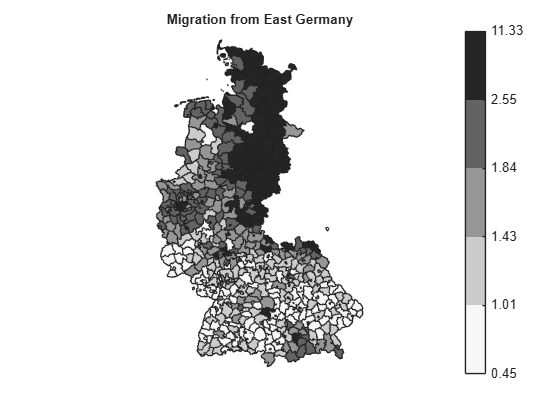

In [29]:
col = 'gdr';

% Share of the 1950 population in %
base = population_1939_ipums(:, {'Shape', col});
base{:, col} = base{:, col} ./ population_1939_ipums.total_population .* 100;

fig = plot_quintile_map(base, col, ...
    'Migration from East Germany', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '03_map_migration_east_germany.png'), Resolution=300);
end

## Map: migration from Berlin

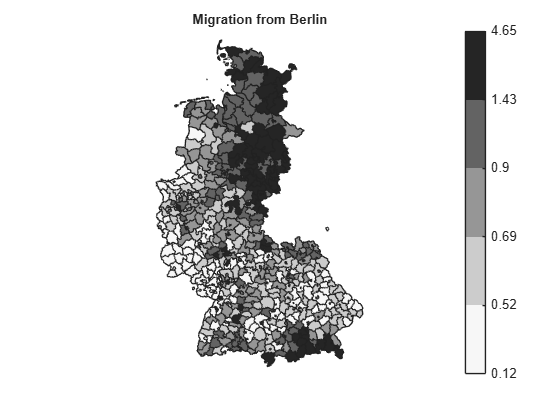

In [30]:
col = 'berlin';

% Share of the 1950 population in %
base = population_1939_ipums(:, {'Shape', col});
base{:, col} = base{:, col} ./ population_1939_ipums.total_population .* 100;

fig = plot_quintile_map(base, col, ...
    'Migration from Berlin', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '04_map_migration_berlin.png'), Resolution=300);
end

## Map: migration from the eastern territories and the Saar region

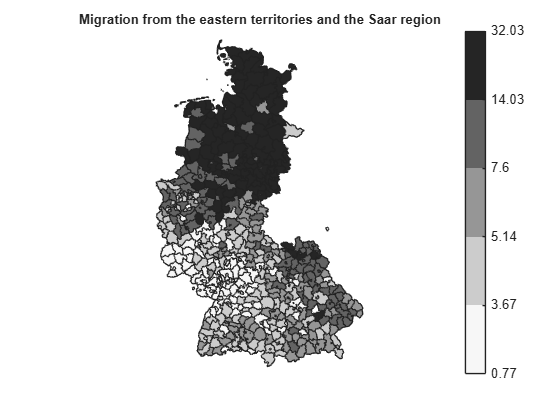

In [ ]:
col = 'east_admin_and_saar';

% Share of the 1950 population in %
base = population_1939_ipums(:, {'Shape', col});
base{:, col} = base{:, col} ./ population_1939_ipums.total_population .* 100;

fig = plot_quintile_map(base, col, ...
    'Migration from the eastern territories and the Saar region', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '05_map_migration_eastern_territories.png'), Resolution=300);
end

## Bar chart: migration from East Germany, Berlin and the eastern territories

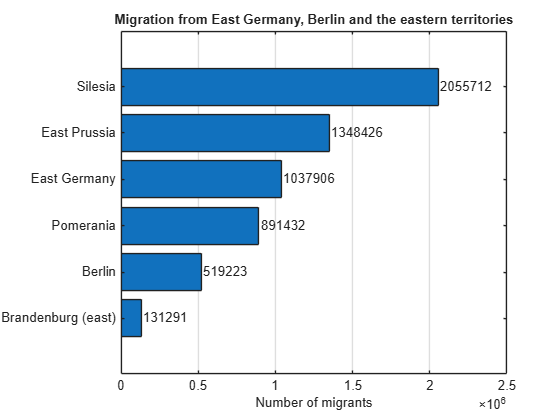

In [32]:
% Columns of the eastern territories and their chart labels
east_cols = {'silesia', 'brandenburg', 'pomerania', 'east_prussia'};
east_labels = {'Silesia', 'Brandenburg (east)', 'Pomerania', 'East Prussia'};

% Totals over all states
east_sums = sum(state_1939{:, east_cols}, 1, 'omitnan');
berlin_sum = sum(state_1939.berlin, 'omitnan');
gdr_sum = sum(state_1939.gdr, 'omitnan');

% Sort the totals (ascending, so the largest bar is on top)
totals = [gdr_sum, berlin_sum, east_sums];
[sorted_totals, idx] = sort(totals);

% Labels in the same order as the totals
chart_labels = [{'East Germany', 'Berlin'}, east_labels];
sorted_labels = chart_labels(idx);

% Chart
fig = figure();

b = barh(sorted_totals);

yticks(1:length(sorted_labels));
yticklabels(sorted_labels);

set(gca, 'XGrid', 'on');

xlabel('Number of migrants');
title('Migration from East Germany, Berlin and the eastern territories');

% Value labels next to the bars
label_x = b.YEndPoints + 0.005 * max(xticks); % Small shift to the right
label_y = b.XEndPoints;

value_labels = string(sorted_totals);

text(label_x, label_y, value_labels, 'HorizontalAlignment', 'left', ...
    'VerticalAlignment', 'middle', 'FontSize', 8);

fontsize(fig, myfontsize, "points")

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '06_migration_east_germany_berlin_territories.png'), Resolution=300);
end

## Map: countries of origin named in the census

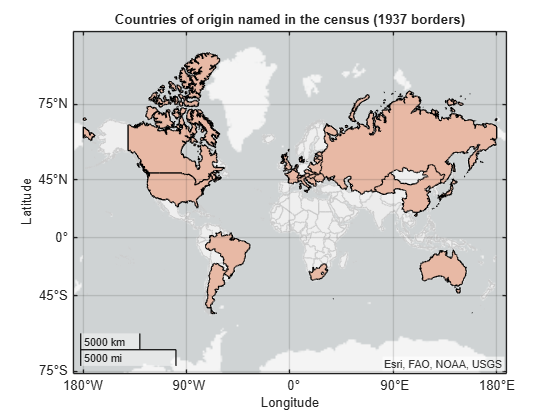

In [33]:
% World borders valid in 1937 (CShapes 2.0)
world_gis = readgeotable('cshapes/CShapes-2.0.shp');
world_1937_gis = world_gis( ...
    world_gis.gwsyear <= 1937 & world_gis.gweyear >= 1937, :);

% All countries named in the census table
origin_countries = { ...
    'Austria', 'Czechoslovakia', 'Poland', 'Gdansk', ...
    'Switzerland', 'Soviet Union', 'Estonia', 'Latvia', ...
    'Lithuania', 'Hungary', 'Yugoslavia', 'Romania', ...
    'Italy', 'France', 'Belgium', 'Netherlands', ...
    'Luxembourg', 'Great Britain', 'Denmark', 'China', ...
    'Japan', 'USA', 'Canada', 'Brazil', ...
    'Argentina', 'South Africa', 'Australia', 'Germany' ...
};

% Some names differ in CShapes
census_names = {'Gdansk', 'Soviet Union', 'Romania', 'Italy', ...
    'Great Britain', 'USA'};
cshapes_names = {'Danzig', 'Russia (Soviet Union)', 'Rumania', ...
    'Italy/Sardinia', 'United Kingdom', 'United States of America'};
origin_countries_mapped = replace(origin_countries, census_names, cshapes_names);

% Select the shapes of the named countries
is_origin = ismember(world_1937_gis.cntry_name, origin_countries_mapped);
origin_gis = world_1937_gis(is_origin, :);

% Chart
fig = figure();

geoplot(world_1937_gis, 'FaceColor', [0.9 0.9 0.9], 'EdgeColor', [0.8 0.8 0.8]);
hold on;

geoplot(origin_gis, 'FaceColor', '#D95319', 'EdgeColor', 'black');

title('Countries of origin named in the census (1937 borders)');

fontsize(fig, myfontsize, "points")

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '07_map_countries_of_origin.png'), Resolution=300);
end

## Bar chart: migration from European countries

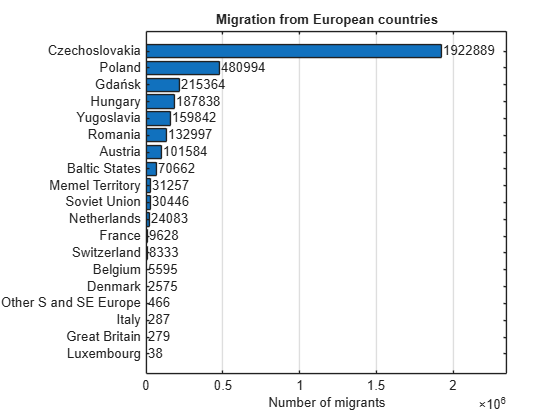

In [34]:
% European columns and their chart labels (same order)
europe_cols = { ...
    'austria', 'czechoslovakia', 'poland', 'gdansk', 'switzerland', ...
    'soviet_union', 'former_baltic_states', 'former_memel_territory', ...
    'hungary', 'yugoslavia', 'romania', 'italy', 'rest_of_south_and_southeast_europe', ...
    'france', 'belgium', 'netherlands', 'luxembourg', 'great_britain', 'denmark'
};
europe_labels = { ...
    'Austria', 'Czechoslovakia', 'Poland', 'Gdańsk', 'Switzerland', ...
    'Soviet Union', 'Baltic States', 'Memel Territory', ...
    'Hungary', 'Yugoslavia', 'Romania', 'Italy', 'Other S and SE Europe', ...
    'France', 'Belgium', 'Netherlands', 'Luxembourg', 'Great Britain', 'Denmark'
};

% Totals over all states
europe_sums = sum(state_1939{:, europe_cols}, 1, 'omitnan');

% Sort (descending, reversed y-axis puts the largest bar on top)
[sorted_sums, idx] = sort(europe_sums, 'descend');
sorted_labels = europe_labels(idx);

% Chart
fig = figure();

b = barh(sorted_sums);

yticks(1:length(sorted_labels));
yticklabels(sorted_labels);

set(gca, 'YDir', 'reverse');
set(gca, 'XGrid', 'on');

xlabel('Number of migrants');
title('Migration from European countries');

% Value labels next to the bars
label_x = b.YEndPoints + 0.005 * max(xticks); % Small shift to the right
label_y = b.XEndPoints;

xlim([0, 2350000])

value_labels = string(sorted_sums);

text(label_x, label_y, value_labels, 'HorizontalAlignment', 'left', ...
    'VerticalAlignment', 'middle', 'FontSize', 8);

fontsize(fig, myfontsize, "points")

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '08_migration_european_countries.png'), Resolution=300);
end

## Map: migration from Czechoslovakia

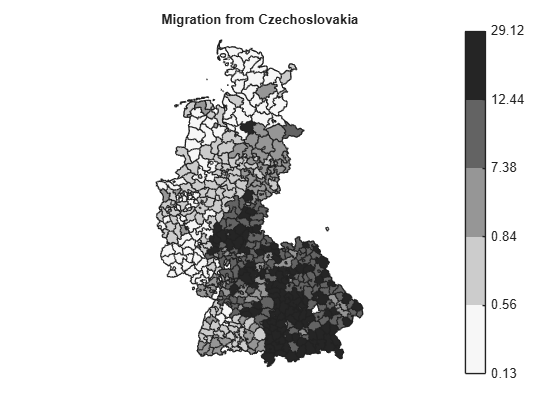

In [35]:
col = 'czechoslovakia';

% Share of the 1950 population in %
base = population_1939_ipums(:, {'Shape', col});
base{:, col} = base{:, col} ./ population_1939_ipums.total_population .* 100;

fig = plot_quintile_map(base, col, ...
    'Migration from Czechoslovakia', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '09_map_migration_czechoslovakia.png'), Resolution=300);
end

## Map: migration from Poland

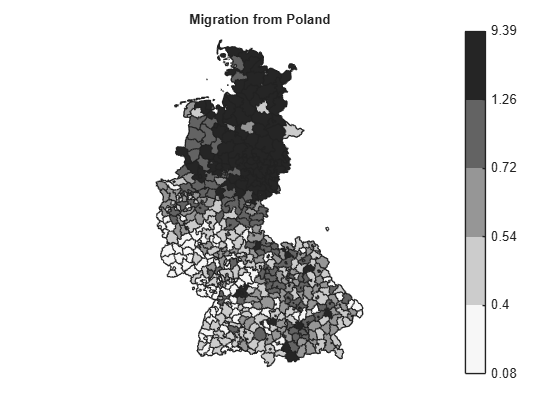

In [36]:
col = 'poland';

% Share of the 1950 population in %
base = population_1939_ipums(:, {'Shape', col});
base{:, col} = base{:, col} ./ population_1939_ipums.total_population .* 100;

fig = plot_quintile_map(base, col, ...
    'Migration from Poland', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '10_map_migration_poland.png'), Resolution=300);
end

## Bar chart: migration from non-European countries

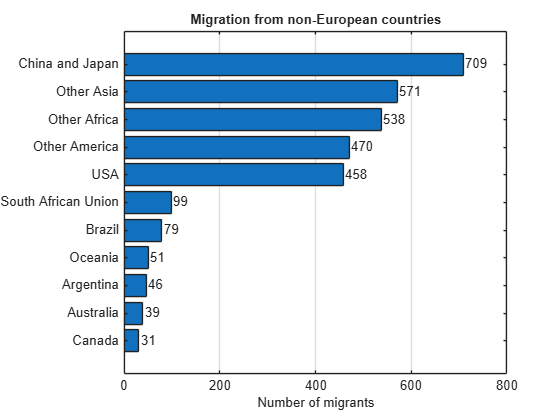

In [37]:
% Non-European columns and their chart labels (same order)
world_cols = { ...
    'china_and_japan', 'rest_of_asia', 'usa', 'canada', 'brazil', ...
    'argentina', 'rest_of_america', 'south_african_union', ...
    'rest_of_africa', 'australia', 'oceania' ...
};
world_labels = { ...
    'China and Japan', 'Other Asia', 'USA', 'Canada', 'Brazil', ...
    'Argentina', 'Other America', 'South African Union', ...
    'Other Africa', 'Australia', 'Oceania' ...
};

% Totals over all states
world_sums = sum(state_1939{:, world_cols}, 1, 'omitnan');

% Sort (ascending, so the largest bar is on top)
[sorted_sums, idx] = sort(world_sums);
sorted_labels = world_labels(idx);

% Chart
fig = figure();

b = barh(sorted_sums);

yticks(1:length(sorted_labels));
yticklabels(sorted_labels);

set(gca, 'XGrid', 'on');

xlabel('Number of migrants');
title('Migration from non-European countries');

% Value labels next to the bars
label_x = b.YEndPoints + 0.005 * max(xticks); % Small shift to the right
label_y = b.XEndPoints;

value_labels = string(sorted_sums);

text(label_x, label_y, value_labels, 'HorizontalAlignment', 'left', ...
    'VerticalAlignment', 'middle', 'FontSize', 8);

fontsize(fig, myfontsize, "points")

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '11_migration_non_european_countries.png'), Resolution=300);
end

## Map: migration from abroad

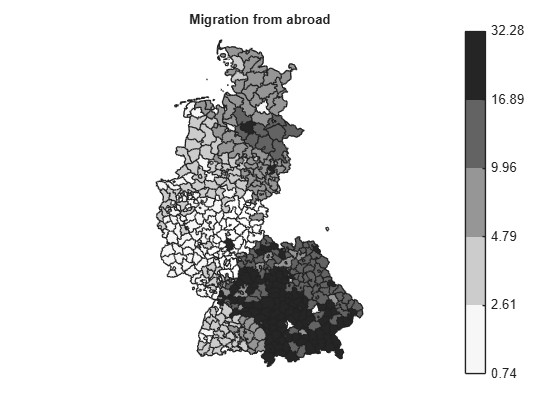

In [38]:
col = 'abroad';

% Share of the 1950 population in %
base = population_1939_ipums(:, {'Shape', col});
base{:, col} = base{:, col} ./ population_1939_ipums.total_population .* 100;

fig = plot_quintile_map(base, col, ...
    'Migration from abroad', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '12_map_migration_abroad.png'), Resolution=300);
end

## Map: all expellees in West Germany

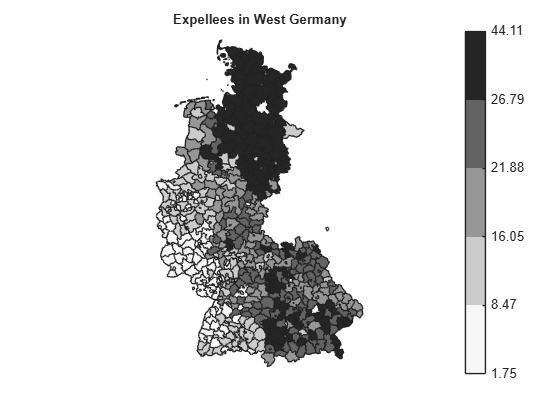

In [39]:
col = 'total_expellees';

% Share of the 1950 population in %
base = expellee_population_ipums(:, {'Shape', col});
base{:, col} = base{:, col} ./ expellee_population_ipums.total_population .* 100;

fig = plot_quintile_map(base, col, ...
    'Expellees in West Germany', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '13_map_all_expellees.png'), Resolution=300);
end

## Map: share of dwellings damaged in the war

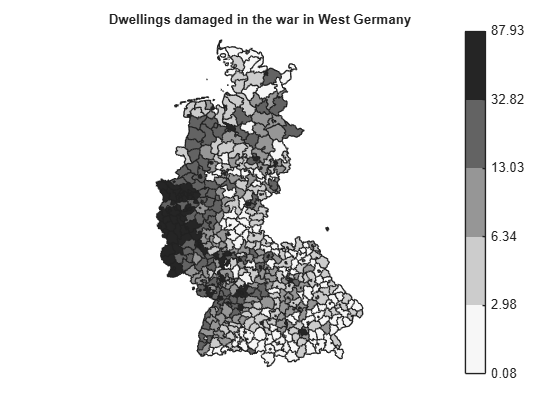

In [40]:
col = 'damaged_percentage';

% Already a share in %, no division needed
base = war_destruction_ipums(:, {'Shape', col});

fig = plot_quintile_map(base, col, ...
    'Dwellings damaged in the war in West Germany', ...
    my_step_colormap, myfontsize);

% Save the chart
if SAVE
    exportgraphics(fig, fullfile(chart_folder, '14_map_war_damaged_dwellings.png'), Resolution=300);
end